In [1]:
import sys
from pathlib import Path

HICOLA_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts' / 'hicola_paths.py').exists())
sys.path.insert(0, str(HICOLA_ROOT / 'scripts'))
import hicola_paths as hp

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def load_power_spectrum(file):

    table = pd.read_csv(file,
    sep=r"\s+",
    comment="#",
    names=["k (h/Mpc)", "P_k (Mpc/h)^3", "P_linear_k (Mpc/h)^3"])

    k = table["k (h/Mpc)"]
    Pk = table["P_k (Mpc/h)^3"]

    return k, Pk

# Load power spectra

In [3]:
import os

# The Abacus matter P(k) is computed by a batch job, not inline here: painting the full
# particle subsample (halo-bound + field particles) onto a mesh needs several GB, which
# doesn't fit in a shared login-node session. Run it with:
#   jobs/submit_power_spectrum_abacus.sh
# (edit the "user parameters" block at the top of jobs/power_spectrum_abacus.sh first if the
# redshift changed). It writes the Abacus_Small reference file in Bart's column format, so it
# loads with the existing load_power_spectrum() helper.

abacus_model = "LCDM"
abacus_redshift = 0.500  # matches REDSHIFT in power_spectrum_abacus.sh
abacus_redshift_label = f"{abacus_redshift:.3f}"

abacus_pk_file = hp.reference_file('Abacus_Small', abacus_model, 1, abacus_redshift, 'PS')

if not os.path.exists(abacus_pk_file):
    raise FileNotFoundError(
        f"Missing {abacus_pk_file}. Run jobs/submit_power_spectrum_abacus.sh first."
    )

k_LCDM_Abacus, Pk_LCDM_Abacus = load_power_spectrum(abacus_pk_file)

# Our own COLA runs to compare against the Abacus box, in two flavours plotted together:
#  - "unfixed": a single realisation on the LCDM_Abacus/nDGP_Abacus box (as in
#    power_spectrum2_Abacus.ipynb).
#  - "paired-fixed": the mean of a fixed-phase / inverse-phase pair ("_a"/"_ma") run on
#    the same box, which cancels most of the sample variance from a single realisation
#    (as in power_spectrum2bis_Abacus.ipynb).
# The nDGP "unfixed" comparison uses nDGP_Abacus rather than the old nDGP1dot0_Abacus
# path (which no longer exists on scratch) -- it's the same box, just the current name.

k_LCDM_Abacus_Unfixed, Pk_LCDM_Abacus_Unfixed = load_power_spectrum(
    hp.pofk_file('Abacus_Small', 'LCDM', 's1234', abacus_redshift)
)
k_nDGP_Abacus_Unfixed, Pk_nDGP_Abacus_Unfixed = load_power_spectrum(
    hp.pofk_file('Abacus_Small', 'nDGP_N1.2', 's1234', abacus_redshift)
)

k_LCDM_Abacus_a, Pk_LCDM_Abacus_a = load_power_spectrum(
    hp.pofk_file('Abacus_Small', 'LCDM', 's1234-fixed', abacus_redshift)
)
k_LCDM_Abacus_ma, Pk_LCDM_Abacus_ma = load_power_spectrum(
    hp.pofk_file('Abacus_Small', 'LCDM', 's1234-fixed-inv', abacus_redshift)
)
assert np.allclose(k_LCDM_Abacus_a, k_LCDM_Abacus_ma), "LCDM s1234-fixed/-fixed-inv k-grids differ"
k_LCDM_Abacus_PairedFixed = k_LCDM_Abacus_a
Pk_LCDM_Abacus_PairedFixed = (Pk_LCDM_Abacus_a + Pk_LCDM_Abacus_ma) / 2

k_nDGP_Abacus_a, Pk_nDGP_Abacus_a = load_power_spectrum(
    hp.pofk_file('Abacus_Small', 'nDGP_N1.2', 's1234-fixed', abacus_redshift)
)
k_nDGP_Abacus_ma, Pk_nDGP_Abacus_ma = load_power_spectrum(
    hp.pofk_file('Abacus_Small', 'nDGP_N1.2', 's1234-fixed-inv', abacus_redshift)
)
assert np.allclose(k_nDGP_Abacus_a, k_nDGP_Abacus_ma), "nDGP s1234-fixed/-fixed-inv k-grids differ"
k_nDGP_Abacus_PairedFixed = k_nDGP_Abacus_a
Pk_nDGP_Abacus_PairedFixed = (Pk_nDGP_Abacus_a + Pk_nDGP_Abacus_ma) / 2


FileNotFoundError: [Errno 2] No such file or directory: '/scratch/biel/LCDM_Abacus/snapshot_LCDM_Abacus_z0.500/pofk_z0.500.txt'

# Plot 1

In [4]:
# Four-panel comparison at z=0.500: LCDM (top row) vs nDGP (bottom row).
# Each COLA panel now shows both flavours of our own runs: a single "unfixed"
# realisation, and the "paired-fixed" mean of a fixed-phase/inverse-phase pair.
k_LCDM_Abacus_plot = np.asarray(k_LCDM_Abacus)
Pk_LCDM_Abacus_plot = np.asarray(Pk_LCDM_Abacus)
abacus_label = r'$\mathrm{Nbody}$'

k_LCDM_Me_plot = np.asarray(k_LCDM_Abacus_Unfixed)
Pk_LCDM_Unfixed_plot = np.asarray(Pk_LCDM_Abacus_Unfixed)
Pk_LCDM_PairedFixed_plot = np.asarray(Pk_LCDM_Abacus_PairedFixed)

k_nDGP_Me_plot = np.asarray(k_nDGP_Abacus_Unfixed)
Pk_nDGP_Unfixed_plot = np.asarray(Pk_nDGP_Abacus_Unfixed)
Pk_nDGP_PairedFixed_plot = np.asarray(Pk_nDGP_Abacus_PairedFixed)

# Cap every curve (including the Abacus comparison itself) at the same max k used in
# power_spectrum2.ipynb's comparison plots -- the Bart box's k range.
k_LCDM_Bart_ref, _ = load_power_spectrum(hp.reference_file('COLA_NM4096', 'LCDM', 1, 1.65, 'PS'))
k_max_ref = np.asarray(k_LCDM_Bart_ref).max()

mask_LCDM_Abacus = k_LCDM_Abacus_plot <= k_max_ref
k_LCDM_Abacus_plot = k_LCDM_Abacus_plot[mask_LCDM_Abacus]
Pk_LCDM_Abacus_plot = Pk_LCDM_Abacus_plot[mask_LCDM_Abacus]

# Cut our LCDM power spectra to the comparison's k range. There is no nDGP N-body
# comparison yet, so the nDGP curves are cut to the same k range as the LCDM comparison instead.
# LCDM_Unfixed/PairedFixed and nDGP_Unfixed/PairedFixed each share a k-grid within their
# model, so one mask per model is enough.
mask_LCDM_Me = (k_LCDM_Me_plot >= k_LCDM_Abacus_plot.min()) & (k_LCDM_Me_plot <= k_max_ref)
k_LCDM_Me_plot = k_LCDM_Me_plot[mask_LCDM_Me]
Pk_LCDM_Unfixed_plot = Pk_LCDM_Unfixed_plot[mask_LCDM_Me]
Pk_LCDM_PairedFixed_plot = Pk_LCDM_PairedFixed_plot[mask_LCDM_Me]

mask_nDGP_Me = (k_nDGP_Me_plot >= k_LCDM_Abacus_plot.min()) & (k_nDGP_Me_plot <= k_max_ref)
k_nDGP_Me_plot = k_nDGP_Me_plot[mask_nDGP_Me]
Pk_nDGP_Unfixed_plot = Pk_nDGP_Unfixed_plot[mask_nDGP_Me]
Pk_nDGP_PairedFixed_plot = Pk_nDGP_PairedFixed_plot[mask_nDGP_Me]

Pk_LCDM_Unfixed_on_Abacus = np.interp(k_LCDM_Abacus_plot, k_LCDM_Me_plot, Pk_LCDM_Unfixed_plot)
Pk_LCDM_PairedFixed_on_Abacus = np.interp(k_LCDM_Abacus_plot, k_LCDM_Me_plot, Pk_LCDM_PairedFixed_plot)
# A handful of the largest-scale Abacus bins have only a few Fourier modes, so shot-noise
# subtraction can push them to ~0 or slightly negative -- exclude those from the ratio.
mask_lcdm_ratio_valid = Pk_LCDM_Abacus_plot > 0
Pk_LCDM_Unfixed_over_Abacus = Pk_LCDM_Unfixed_on_Abacus / Pk_LCDM_Abacus_plot
Pk_LCDM_PairedFixed_over_Abacus = Pk_LCDM_PairedFixed_on_Abacus / Pk_LCDM_Abacus_plot

fig_size = (6.6, 4.35)
label_size = 10.5
tick_size = 8.8
legend_size = 7.6
line_width = 1.45
cola_unfixed_color = '#e0a458'
cola_paired_color = '#c47f2b'
abacus_color = '#1f4e79'
ratio_unfixed_color = '#6fb3b0'
ratio_paired_color = '#2b7a78'
ref_color = '0.35'

fig, axes = plt.subplots(2, 2, figsize=fig_size, dpi=300, constrained_layout=True)
ax_tl, ax_tr = axes[0]
ax_bl, ax_br = axes[1]

# Top row: LCDM
ax_tl.semilogx(k_LCDM_Me_plot, k_LCDM_Me_plot**(3/2) * Pk_LCDM_Unfixed_plot, lw=line_width, color=cola_unfixed_color, ls='-.', label=r'$\mathrm{COLA\ (unfixed)}$')
ax_tl.semilogx(k_LCDM_Me_plot, k_LCDM_Me_plot**(3/2) * Pk_LCDM_PairedFixed_plot, lw=line_width, color=cola_paired_color, ls='--', label=r'$\mathrm{COLA\ (paired-fixed)}$')
ax_tl.semilogx(k_LCDM_Abacus_plot, k_LCDM_Abacus_plot**(3/2) * Pk_LCDM_Abacus_plot, lw=line_width, color=abacus_color, label=abacus_label)
ax_tl.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_tl.set_ylabel(r'$k^{3/2} P(k)$', fontsize=label_size)
ax_tl.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_tl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

ax_tr.semilogx(k_LCDM_Abacus_plot[mask_lcdm_ratio_valid], Pk_LCDM_Unfixed_over_Abacus[mask_lcdm_ratio_valid], lw=line_width, color=ratio_unfixed_color, ls='-.', label=r'$\mathrm{unfixed}$')
ax_tr.semilogx(k_LCDM_Abacus_plot[mask_lcdm_ratio_valid], Pk_LCDM_PairedFixed_over_Abacus[mask_lcdm_ratio_valid], lw=line_width, color=ratio_paired_color, ls='--', label=r'$\mathrm{paired-fixed}$')
ax_tr.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_tr.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_tr.set_ylabel(r'$P_{\mathrm{COLA}} / P_{\mathrm{Nbody}}$', fontsize=label_size)
ax_tr.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_tr.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

# Bottom row: nDGP -- no N-body nDGP comparison yet, so only our two simulation flavours are shown
ax_bl.semilogx(k_nDGP_Me_plot, k_nDGP_Me_plot**(3/2) * Pk_nDGP_Unfixed_plot, lw=line_width, color=cola_unfixed_color, ls='-.', label=r'$\mathrm{COLA\ (unfixed)}$')
ax_bl.semilogx(k_nDGP_Me_plot, k_nDGP_Me_plot**(3/2) * Pk_nDGP_PairedFixed_plot, lw=line_width, color=cola_paired_color, ls='--', label=r'$\mathrm{COLA\ (paired-fixed)}$')
ax_bl.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_bl.set_ylabel(r'$k^{3/2} P(k)$', fontsize=label_size)
ax_bl.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)
ax_bl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)
ax_bl.set_xlim(ax_tl.get_xlim())
#ax_bl.set_ylim(ax_tl.get_ylim())

# No N-body nDGP comparison available yet, so this panel shows our own nDGP/LCDM
# ratio instead (previously a separate standalone figure), for both flavours.
Pk_nDGP_Unfixed_on_LCDM = np.interp(k_LCDM_Me_plot, k_nDGP_Me_plot, Pk_nDGP_Unfixed_plot)
Pk_nDGP_PairedFixed_on_LCDM = np.interp(k_LCDM_Me_plot, k_nDGP_Me_plot, Pk_nDGP_PairedFixed_plot)
ax_br.semilogx(k_LCDM_Me_plot, Pk_nDGP_Unfixed_on_LCDM / Pk_LCDM_Unfixed_plot, lw=line_width, color=cola_unfixed_color, ls='-.', label=r'$\mathrm{COLA\ (unfixed)}$')
ax_br.semilogx(k_LCDM_Me_plot, Pk_nDGP_PairedFixed_on_LCDM / Pk_LCDM_PairedFixed_plot, lw=line_width, color=cola_paired_color, ls='--', label=r'$\mathrm{COLA\ (paired-fixed)}$')
ax_br.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_br.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_br.set_ylabel(r'$P_{\mathrm{nDGP}} / P_{\mathrm{LCDM}}$', fontsize=label_size)
ax_br.set_ylim(0.8,2.1)
ax_br.set_title(r'$\mathrm{nDGP}/\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_br.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25, loc='upper left')

for ax in (ax_tl, ax_tr, ax_bl, ax_br):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.45)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=3.4, width=0.7)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 0.8, length=2.0, width=0.55)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)

plt.show()


NameError: name 'k_LCDM_Abacus_Unfixed' is not defined

# Load halo catalogs


In [5]:
def load_hmf_table(file):
    table = np.loadtxt(file, comments='#')
    return table[:, 0], table[:, 1]

# Our own COLA HMFs (no N-body HMF comparison available yet -- Abacus1's halo catalog
# is only in raw CompaSO/ASDF format, not processed into this n(>M) format).
# As with the power spectrum, two variants are loaded:
#  - "unmatched": a single, ordinary realisation of each box.
#  - "paired-matched": the mean over the fixed-phase / inverse-phase pair (_a / _ma).
# NOTE: the paired-matched halo catalogs (_a / _ma) don't exist yet -- this cell will
# raise FileNotFoundError until they are produced, at which point it should just work.
LCDM_hmf_file_unmatched = hp.hmf_file('Abacus_Small', 'LCDM', 's1234', abacus_redshift)
nDGP_hmf_file_unmatched = hp.hmf_file('Abacus_Small', 'nDGP_N1.2', 's1234', abacus_redshift)

M_LCDM_Me_unmatched, hmf_LCDM_Me_unmatched = load_hmf_table(LCDM_hmf_file_unmatched)
M_nDGP_Me_unmatched, hmf_nDGP_Me_unmatched = load_hmf_table(nDGP_hmf_file_unmatched)

LCDM_hmf_file_a = hp.hmf_file('Abacus_Small', 'LCDM', 's1234-fixed', abacus_redshift)
LCDM_hmf_file_ma = hp.hmf_file('Abacus_Small', 'LCDM', 's1234-fixed-inv', abacus_redshift)
nDGP_hmf_file_a = hp.hmf_file('Abacus_Small', 'nDGP_N1.2', 's1234-fixed', abacus_redshift)
nDGP_hmf_file_ma = hp.hmf_file('Abacus_Small', 'nDGP_N1.2', 's1234-fixed-inv', abacus_redshift)

M_LCDM_a, hmf_LCDM_a = load_hmf_table(LCDM_hmf_file_a)
M_LCDM_ma, hmf_LCDM_ma = load_hmf_table(LCDM_hmf_file_ma)
assert np.allclose(M_LCDM_a, M_LCDM_ma), "LCDM s1234-fixed/-fixed-inv HMF mass bins differ"
M_LCDM_Me_matched = M_LCDM_a
hmf_LCDM_Me_matched = (hmf_LCDM_a + hmf_LCDM_ma) / 2

M_nDGP_a, hmf_nDGP_a = load_hmf_table(nDGP_hmf_file_a)
M_nDGP_ma, hmf_nDGP_ma = load_hmf_table(nDGP_hmf_file_ma)
assert np.allclose(M_nDGP_a, M_nDGP_ma), "nDGP s1234-fixed/-fixed-inv HMF mass bins differ"
M_nDGP_Me_matched = M_nDGP_a
hmf_nDGP_Me_matched = (hmf_nDGP_a + hmf_nDGP_ma) / 2

# Plot 6


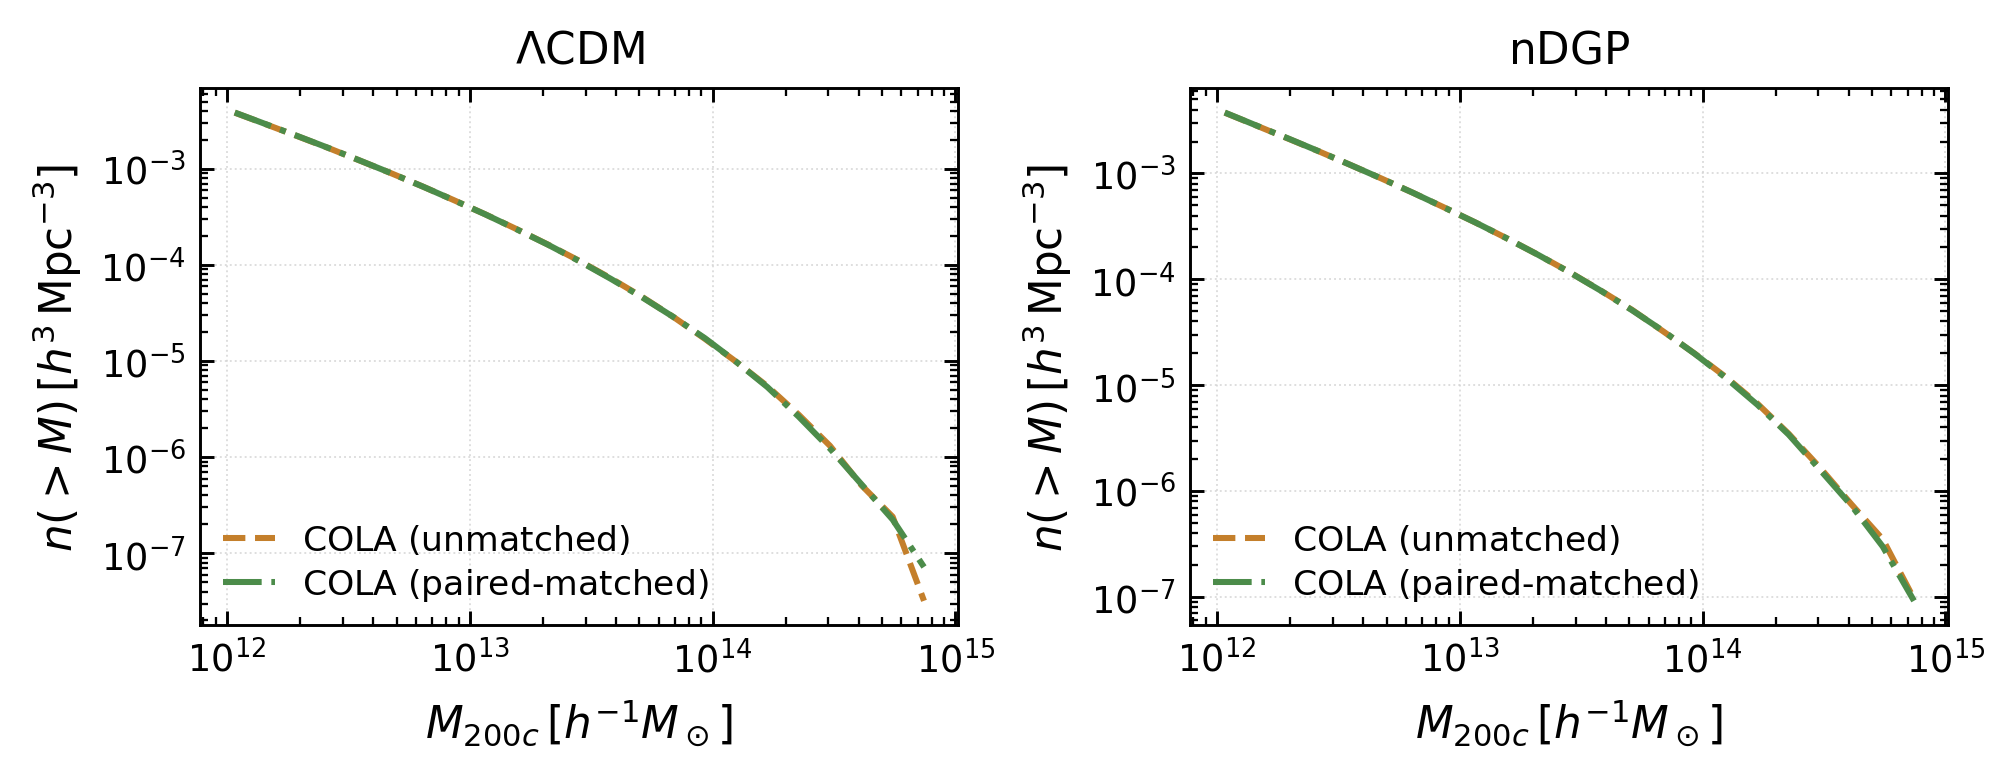

In [6]:
# Two-panel HMF comparison at z=0.500 (COLA only -- no N-body HMF comparison yet)
# Both COLA variants are shown: "unmatched" (single realisation) and "paired-matched"
# (mean of the fixed-phase / inverse-phase pair).
M_LCDM_unmatched_plot = np.asarray(M_LCDM_Me_unmatched)
hmf_LCDM_unmatched_plot = np.asarray(hmf_LCDM_Me_unmatched)
M_nDGP_unmatched_plot = np.asarray(M_nDGP_Me_unmatched)
hmf_nDGP_unmatched_plot = np.asarray(hmf_nDGP_Me_unmatched)

M_LCDM_matched_plot = np.asarray(M_LCDM_Me_matched)
hmf_LCDM_matched_plot = np.asarray(hmf_LCDM_Me_matched)
M_nDGP_matched_plot = np.asarray(M_nDGP_Me_matched)
hmf_nDGP_matched_plot = np.asarray(hmf_nDGP_Me_matched)

fig_size = (6.6, 4.35)
label_size = 10.5
tick_size = 8.8
legend_size = 8.3
line_width = 1.45
cola_unmatched_color = '#c47f2b'
cola_matched_color = '#4c8c4a'

fig, axes = plt.subplots(2, 2, figsize=fig_size, dpi=300, constrained_layout=True)
ax_l, ax_r = axes[0]
ax_bl, ax_br = axes[1]

mask_lcdm_unmatched = (hmf_LCDM_unmatched_plot > 0) & (M_LCDM_unmatched_plot >= 1e12)
mask_lcdm_matched = (hmf_LCDM_matched_plot > 0) & (M_LCDM_matched_plot >= 1e12)
ax_l.loglog(M_LCDM_unmatched_plot[mask_lcdm_unmatched], hmf_LCDM_unmatched_plot[mask_lcdm_unmatched], lw=line_width, color=cola_unmatched_color, ls='--', label=r'$\mathrm{COLA\ (unmatched)}$')
ax_l.loglog(M_LCDM_matched_plot[mask_lcdm_matched], hmf_LCDM_matched_plot[mask_lcdm_matched], lw=line_width, color=cola_matched_color, ls='-.', label=r'$\mathrm{COLA\ (paired\text{-}matched)}$')
ax_l.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_l.set_ylabel(r'$n(>M)\,[h^3\,\mathrm{Mpc}^{-3}]$', fontsize=label_size)
ax_l.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_l.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

mask_ndgp_unmatched = (hmf_nDGP_unmatched_plot > 0) & (M_nDGP_unmatched_plot >= 1e12)
mask_ndgp_matched = (hmf_nDGP_matched_plot > 0) & (M_nDGP_matched_plot >= 1e12)
ax_r.loglog(M_nDGP_unmatched_plot[mask_ndgp_unmatched], hmf_nDGP_unmatched_plot[mask_ndgp_unmatched], lw=line_width, color=cola_unmatched_color, ls='--', label=r'$\mathrm{COLA\ (unmatched)}$')
ax_r.loglog(M_nDGP_matched_plot[mask_ndgp_matched], hmf_nDGP_matched_plot[mask_ndgp_matched], lw=line_width, color=cola_matched_color, ls='-.', label=r'$\mathrm{COLA\ (paired\text{-}matched)}$')
ax_r.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_r.set_ylabel(r'$n(>M)\,[h^3\,\mathrm{Mpc}^{-3}]$', fontsize=label_size)
ax_r.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)
ax_r.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

ax_bl.set_visible(False)
ax_br.set_visible(False)

for ax in (ax_l, ax_r):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.45)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=3.4, width=0.7)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 0.8, length=2.0, width=0.55)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)

plt.show()

## Plot 6b: nDGP/LCDM HMF ratio (standalone, one-column figure)


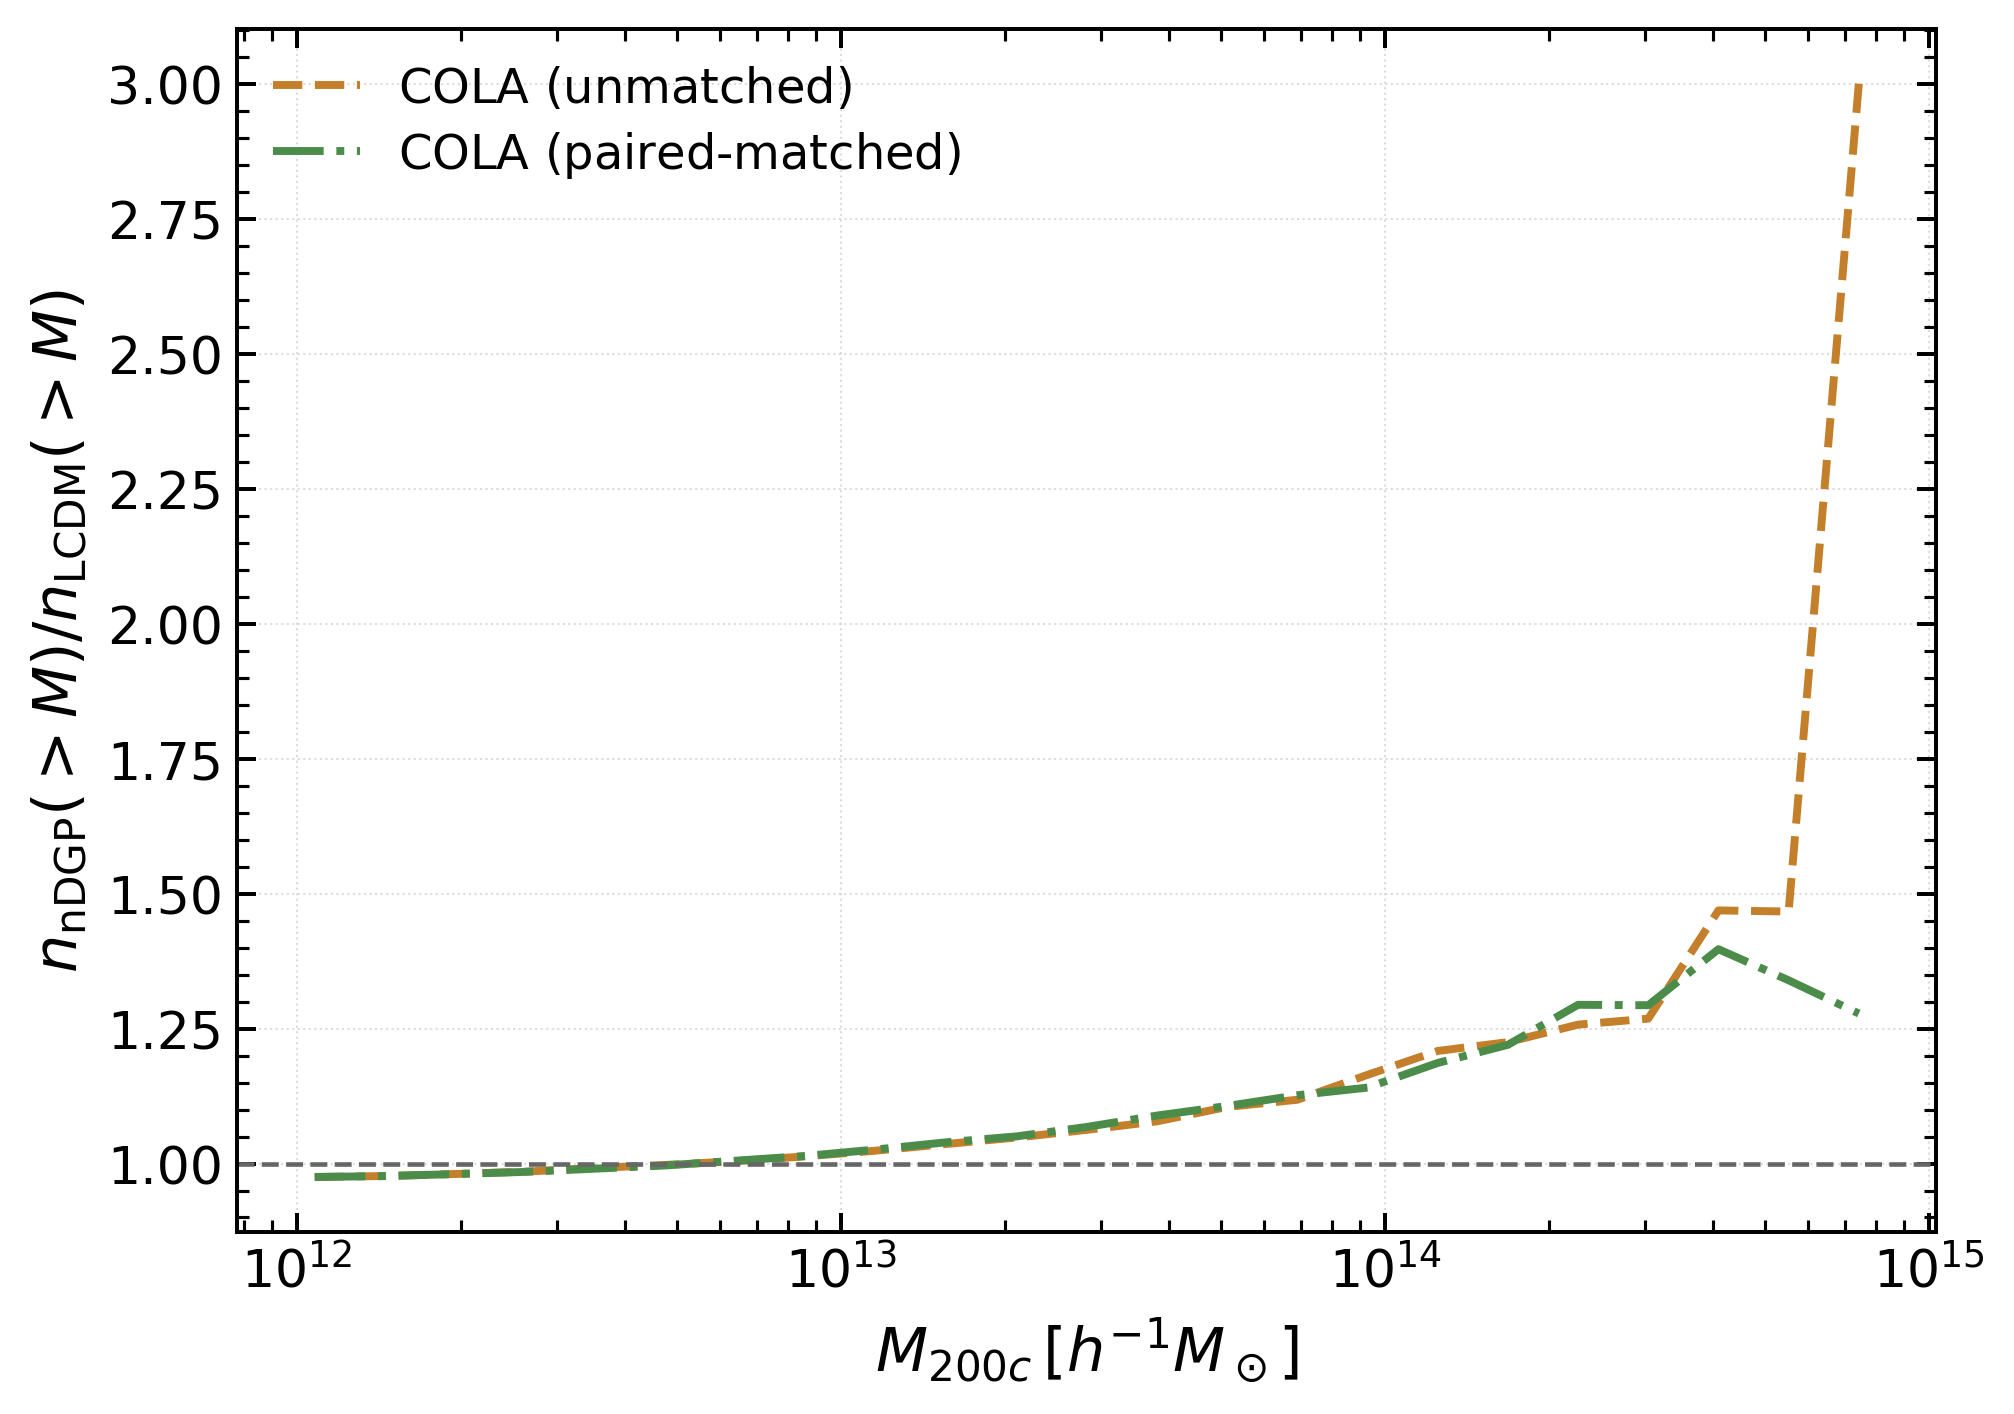

In [7]:
# nDGP / LCDM HMF ratio at z=0.500 (COLA only -- no N-body HMF comparison yet)
# Both COLA variants are shown: "unmatched" (single realisation) and "paired-matched"
# (mean of the fixed-phase / inverse-phase pair).
M_LCDM_unmatched_plot = np.asarray(M_LCDM_Me_unmatched)
hmf_LCDM_unmatched_plot = np.asarray(hmf_LCDM_Me_unmatched)
M_nDGP_unmatched_plot = np.asarray(M_nDGP_Me_unmatched)
hmf_nDGP_unmatched_plot = np.asarray(hmf_nDGP_Me_unmatched)

M_LCDM_matched_plot = np.asarray(M_LCDM_Me_matched)
hmf_LCDM_matched_plot = np.asarray(hmf_LCDM_Me_matched)
M_nDGP_matched_plot = np.asarray(M_nDGP_Me_matched)
hmf_nDGP_matched_plot = np.asarray(hmf_nDGP_Me_matched)

hmf_nDGP_unmatched_on_LCDM = np.interp(M_LCDM_unmatched_plot, M_nDGP_unmatched_plot, hmf_nDGP_unmatched_plot)
hmf_nDGP_over_LCDM_unmatched = np.divide(
    hmf_nDGP_unmatched_on_LCDM,
    hmf_LCDM_unmatched_plot,
    out=np.full_like(hmf_LCDM_unmatched_plot, np.nan, dtype=float),
    where=hmf_LCDM_unmatched_plot > 0,
)
mask_ratio_unmatched = np.isfinite(hmf_nDGP_over_LCDM_unmatched) & (M_LCDM_unmatched_plot >= 1e12)

hmf_nDGP_matched_on_LCDM = np.interp(M_LCDM_matched_plot, M_nDGP_matched_plot, hmf_nDGP_matched_plot)
hmf_nDGP_over_LCDM_matched = np.divide(
    hmf_nDGP_matched_on_LCDM,
    hmf_LCDM_matched_plot,
    out=np.full_like(hmf_LCDM_matched_plot, np.nan, dtype=float),
    where=hmf_LCDM_matched_plot > 0,
)
mask_ratio_matched = np.isfinite(hmf_nDGP_over_LCDM_matched) & (M_LCDM_matched_plot >= 1e12)

# This is a standalone, one-column figure (unlike the two-panel plot above), so it will be
# shrunk more to fit a document column -- sizes here are scaled up accordingly to stay readable.
fig_size = (6.6, 4.6)
label_size = 14.5
tick_size = 12.5
legend_size = 11.5
line_width = 1.9
cola_unmatched_color = '#c47f2b'
cola_matched_color = '#4c8c4a'

fig, ax = plt.subplots(figsize=fig_size, dpi=300, constrained_layout=True)

ax.semilogx(M_LCDM_unmatched_plot[mask_ratio_unmatched], hmf_nDGP_over_LCDM_unmatched[mask_ratio_unmatched], lw=line_width, color=cola_unmatched_color, ls='--', label=r'$\mathrm{COLA\ (unmatched)}$')
ax.semilogx(M_LCDM_matched_plot[mask_ratio_matched], hmf_nDGP_over_LCDM_matched[mask_ratio_matched], lw=line_width, color=cola_matched_color, ls='-.', label=r'$\mathrm{COLA\ (paired\text{-}matched)}$')
ax.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax.set_ylabel(r'$n_{\mathrm{nDGP}}(>M) / n_{\mathrm{LCDM}}(>M)$', fontsize=label_size)
ax.legend(fontsize=legend_size, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)
ax.axhline(1.0, color='0.4', lw=1.1, ls='--')

ax.minorticks_on()
ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.5)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=4.6, width=0.95)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 1.2, length=2.8, width=0.75)
for spine in ax.spines.values():
    spine.set_linewidth(0.95)

plt.show()